# [Link to GitHub Repository](https://github.com/L-nsamba/group-1-formative-3-probability-bayes-gradient-descent.git)

### Importing the relevant and accepted libraries that will be used during the subsequent calculations

In [78]:
import numpy as np
import matplotlib.pyplot as plt
from scipy.optimize import approx_fprime

### Implementing the initial data provided in rubric in code form


In [79]:
# Input matrix
X = np.array([
    [1, 3],
    [4, 10]
], dtype=float)

# Actual output values
y = np.array([5, 6], dtype=float)

# Initial weights and bias
m = np.array([-1, 2], dtype=float)
b = 1.0

# Learning rate and number of iterations
alpha = 0.01
iterations = 3 # Corresponding to the number of team members

# Number of observations
n = len(y)

# Verifying the output
print("Input matrix X:\n", X)
print("Actual outputs y:", y)
print("Initial weights m:", m)
print("Initial bias b:", b)
print("Learning rate:", alpha)
print("Number of iterations:", iterations)

Input matrix X:
 [[ 1.  3.]
 [ 4. 10.]]
Actual outputs y: [5. 6.]
Initial weights m: [-1.  2.]
Initial bias b: 1.0
Learning rate: 0.01
Number of iterations: 3


### Creation of resusable functions for DRY and modular code

In [80]:
# Calculate predictions
def predict(X, m, b):
    return X @ m + b


# Calculate Mean Squared Error
def calculate_mse(y_true, y_pred):
    return np.mean((y_true - y_pred) ** 2)


# Calculate gradients using the chain rule
def calculate_gradients(X, y, m, b):
    errors = predict(X, m, b) - y
    n = len(y)

    dm1 = (2 / n) * np.sum(errors * X[:, 0])
    dm2 = (2 / n) * np.sum(errors * X[:, 1])
    db = (2 / n) * np.sum(errors)

    return np.array([dm1, dm2]), db

### Definition of the predictions and MSE calculations

In [81]:
# Predictions using one shared bias
y_hat = predict(X, m, b)

# Prediction errors
p_error = y_hat - y

# Mean Squared Error
mse = calculate_mse(y, y_hat)

print("Initial predictions:", y_hat)
print("Prediction errors:", p_error)
print(f"Initial MSE: {mse:.2f}")

Initial predictions: [ 6. 17.]
Prediction errors: [ 1. 11.]
Initial MSE: 61.00


### Definition of the MSE cost function

In [82]:
def cost_function(params, X, y):
  # Extracting the weights and bias from each parameter of the array
  m1 = params[0]
  m2 = params[1]
  b = params[2]


  # Calculation of the predictions
  # The same shared bias is added every observation
  y_hat = predict(X, np.array([m1, m2]), b)

  # Calculation and retrieving the value of the MSE
  return calculate_mse(y, y_hat)

# Combining the inital parameters into one array
params = np.array([m[0], m[1], b], dtype=float)
print("Initial cost:", cost_function(params, X, y))

Initial cost: 61.0


### Using SciPy to approximate the derivatives. This is what we use to get gradients for m1, m2 and b (dJ/dm1, dJ/dm2, dJ/db)

In [83]:
# Small step used for numerical differentiation
epsilon = 1e-8

# Approximating the gradient of the cost function
# where fprime is the derivative of f
def compute_derivative(func, params, *args, eps=epsilon):
    return approx_fprime(params, func, eps, *args)

# Passing the MSE cost function into the derivative function
gradient = compute_derivative(cost_function, params, X, y)

print(f"Gradient for m1: {gradient[0]:.2f}")
print(f"Gradient for m2: {gradient[1]:.2f}")
print(f"Gradient for b: {gradient[2]:.2f}")

Gradient for m1: 45.00
Gradient for m2: 113.00
Gradient for b: 12.00


### Calculating the gradients visibly with chain rule for the MSE cost function. This will give us the same answers as the previous cell where we made use of SciPy

In [84]:
# Calculating each gradient explicitly using the chain rule
gradients, db = calculate_gradients(X, y, m, b)
dm1, dm2 = gradients

p_error = predict(X, m, b) - y

print(f"Prediction errors: {p_error}")
print(f"Gradient for m1: {dm1:.2f}")
print(f"Gradient for m2: {dm2:.2f}")
print(f"Gradient for b: {db:.2f}")

Prediction errors: [ 1. 11.]
Gradient for m1: 45.00
Gradient for m2: 113.00
Gradient for b: 12.00


### Implementing the three gradient descent updates

In [85]:
# Storing the initial values for tracking
m_history = [m.copy()]
b_history = [b]

# Calculating the initial MSE
y_hat = predict(X, m, b)
mse_history = [calculate_mse(y, y_hat)]

for iteration in range(1, iterations + 1):

  # Calculating predictions and errors before the update
  y_hat = predict(X, m, b)
  errors = y_hat - y
  mse_before = calculate_mse(y, y_hat)

  # Calculating gradients using the chain rule
  gradients, db = calculate_gradients(X, y, m, b)
  dm1, dm2 = gradients

  # Verifying the manual gradients against SciPy
  current_params = np.array([m[0], m[1], b], dtype=float)
  scipy_grad = approx_fprime(
      current_params, cost_function, 1e-8, X, y
  )
  manual_grad = np.array([dm1, dm2, db])

  grads_match = np.allclose(
      scipy_grad, manual_grad, atol=1e-4 # where atol is the absolute tolerance
  )


  # Updating each parameter
  m[0] = m[0] - alpha * dm1
  m[1] = m[1] - alpha * dm2
  b = b - alpha * db

  # Calculating predictions and MSE after the update
  y_hat = predict(X, m, b)
  mse_after = calculate_mse(y, y_hat)

  # Storing the updated parameters
  m_history.append(m.copy())
  b_history.append(b)
  mse_history.append(mse_after)

  # Displaying the results with corrected indentation
  print(f"\nIteration {iteration}")
  print(f"MSE before update: {mse_before:.2f}")
  print(f"Gradient m1: {dm1:.2f}")
  print(f"Gradient m2: {dm2:.2f}")
  print(f"Gradient b: {db:.2f}")
  print(f"Updated m1: {m[0]:.4f}")
  print(f"Updated m2: {m[1]:.4f}")
  print(f"Updated b: {b:.4f}")
  print(f"Predictions: {y_hat}")
  print(f"MSE after update: {mse_after:.4f}")
  print(f"Manual and SciPy gradients match: {grads_match}")


Iteration 1
MSE before update: 61.00
Gradient m1: 45.00
Gradient m2: 113.00
Gradient b: 12.00
Updated m1: -1.4500
Updated m2: 0.8700
Updated b: 0.8800
Predictions: [2.04 3.78]
MSE after update: 6.8450
Manual and SciPy gradients match: True

Iteration 2
MSE before update: 6.85
Gradient m1: -11.84
Gradient m2: -31.08
Gradient b: -5.18
Updated m1: -1.3316
Updated m2: 1.1808
Updated b: 0.9318
Predictions: [3.1426 7.4134]
MSE after update: 2.7238
Manual and SciPy gradients match: True

Iteration 3
MSE before update: 2.72
Gradient m1: 3.80
Gradient m2: 8.56
Gradient b: -0.44
Updated m1: -1.3696
Updated m2: 1.0952
Updated b: 0.9362
Predictions: [2.852224 6.409812]
MSE after update: 2.3904
Manual and SciPy gradients match: True


### Verifying the final iteration (3) results for weight, bias, predictions and MSE

In [86]:
# Calculating predictions and MSE using the final parameters
final_y_hat = predict(X, m, b)
final_mse = calculate_mse(y, final_y_hat)

print("Final weights:", np.round(m, 2))
print(f"Final shared bias: {b:.2f}")
print("Final predictions:", np.round(final_y_hat, 2))
print(f"Final MSE: {final_mse:.2f}")

Final weights: [-1.37  1.1 ]
Final shared bias: 0.94
Final predictions: [2.85 6.41]
Final MSE: 2.39


### A plot showing how weights (m1, m2) and bias (b) change over iterations

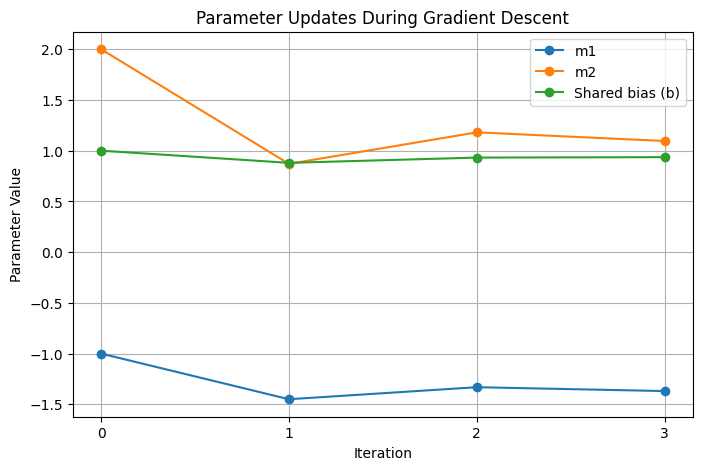

In [87]:
# Plotting parameter updates across iterations
iteration_numbers = range(len(m_history))

plt.figure(figsize=(8, 5))

# m1 plots
plt.plot(iteration_numbers, [m[0] for m in m_history], marker='o', label='m1')

# m2 plots
plt.plot(iteration_numbers, [m[1] for m in m_history], marker='o', label='m2')

# shared bias
plt.plot(iteration_numbers, b_history, marker='o', label='Shared bias (b)')

plt.xlabel('Iteration')
plt.ylabel('Parameter Value')
plt.title('Parameter Updates During Gradient Descent')
plt.xticks(iteration_numbers)
plt.legend()
plt.grid(True)
plt.show()

### Interpretation of the parameter updates during gradient descent

The plot shows how the weights and shared bias change over three gradient descent iterations. The weights adjust to reduce prediction errors, while the shared bias decreases from 1.00 to approximately 0.94. Together, these updates improve the model's predictions.

### A plot showing how the error (mse) changes over iterations.

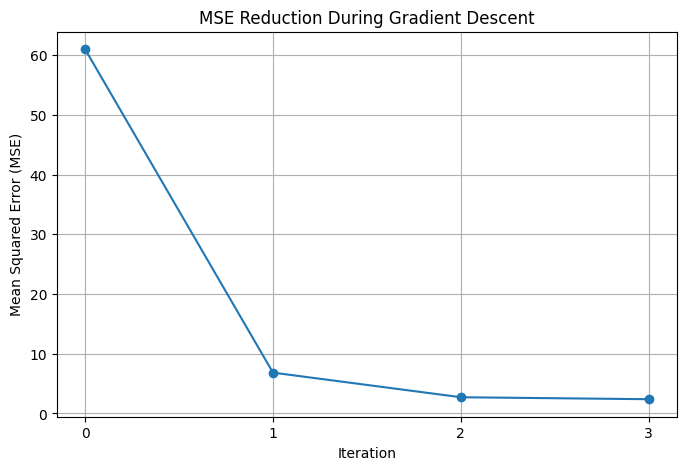

In [88]:
# Plotting MSE across iterations
iteration_numbers = range(len(mse_history))

plt.figure(figsize=(8, 5))

plt.plot(iteration_numbers, mse_history, marker='o')

plt.xlabel('Iteration')
plt.ylabel('Mean Squared Error (MSE)')
plt.title('MSE Reduction During Gradient Descent')
plt.xticks(iteration_numbers)
plt.grid(True)
plt.show()

### Interpretation of the mse reduction during gradient descent

The MSE decreases from 61.00 initially to approximately 6.85, 2.72, and 2.39 after the three updates. The largest improvement occurs in the first iteration. This shows that gradient descent is reducing the prediction error and improving the model's fit to the data.

### Conclusion

We implemented gradient descent to optimize the weights and a single shared bias for a linear regression model over three iterations. The MSE decreased from 61.00 to 2.39, indicating that the model's predictions improved with each update. The final weights were approximately [-1.37, 1.10], and the shared bias was 0.94, producing predictions of [2.85, 6.41]. The manual gradients were also verified against SciPy's numerical derivatives.